# Beating xwOBA with Bat-Tracking Data

**Explanatory vs. predictive expected wOBA-on-contact (xwOBAcon), built from Statcast bat-tracking data (2023–2026).**

This notebook walks through two modeling questions:

| | Part 1 — Explanatory | Part 2 — Predictive |
|---|---|---|
| **Question** | Given how a ball was hit, what was it worth? | Given a hitter's season, what will he do *next* season? |
| **Unit** | One batted ball (395,774 rows) | One batter-season transition (799 rows) |
| **Target** | Actual `woba_value` of that batted ball | Batter's actual wOBAcon in season N+1 |
| **Benchmark** | Statcast `estimated_woba_using_speedangle` | Statcast xwOBAcon in season N, carried forward |
| **Split** | Random 80/20 | Temporal: train 2023→24 + 2024→25, test 2025→26 |

For both parts, **9 model families** (Linear, Lasso, Ridge, ElasticNet, XGBoost, LightGBM, CatBoost, Random Forest, MLP neural net) were each run through **forward and backward stepwise feature selection** over the same 9 candidate features:

`launch_speed` (exit velo) · `launch_angle` · `spray_angle` (derived) · `bat_speed` · `stand` · `swing_length` · `attack_angle` · `attack_direction` · `swing_path_tilt`

> The stepwise searches and hyperparameter tuning runs took several hours and are reproducible with the scripts in `src/`. This notebook loads their saved outputs from `results/`, and **refits the final tuned models from scratch** to produce every evaluation chart.

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import lightgbm as lgb
import xgboost as xgb

warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, RESULTS, FIGS = ROOT / "data", ROOT / "results", ROOT / "figures"
FIGS.mkdir(exist_ok=True)
RNG = 42

# Palette: one accent for candidate models, neutral gray for Statcast, muted for underperformers
ACCENT, ACCENT_DARK, BENCH, MUTED = "#2a78d6", "#184f95", "#8b8c92", "#c9c8c1"
GOOD, BAD, INK = "#0ca30c", "#d03b3b", "#16171a"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "figure.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "axes.titleweight": "bold",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e8e7e1", "grid.linewidth": 0.8,
    "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 10,
    "legend.frameon": False,
})
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_colwidth", 120)

NAMES = {
    "linear_regression": "Linear Regression", "lasso": "Lasso", "ridge": "Ridge",
    "elasticnet": "ElasticNet", "xgboost": "XGBoost", "lightgbm": "LightGBM",
    "catboost": "CatBoost", "random_forest": "Random Forest", "neural_net": "Neural Net (MLP)",
}
RAW_FEATURES = ["launch_speed", "launch_angle", "spray_angle", "bat_speed", "stand_L",
                "swing_length", "attack_angle", "attack_direction", "swing_path_tilt"]

def savefig(fig, name):
    fig.savefig(FIGS / f"{name}.png", bbox_inches="tight")

def metrics(y_true, y_pred):
    r = pearsonr(y_true, y_pred)[0]
    return {
        "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "mae": float(mean_absolute_error(y_true, y_pred)),
        "r2": float(r2_score(y_true, y_pred)),
        "corr": float(r),
        "corr2": float(r ** 2),
    }

def load(name):
    return json.loads((RESULTS / name).read_text())

## 1. The data

Pulled with `baseballr::statcast_search()` **day by day** (Baseball Savant's CSV endpoint silently truncates any query at 25,000 rows — weekly pulls lost data on 92 of 120 weeks). Bat-tracking data begins **2023-07-14**; the pull runs through **2026-09-09**.

Modeling rows are restricted to **wOBA-eligible balls in play** (`type == "X"`, `woba_denom == 1`), matching how Statcast scopes its own xwOBA.

`spray_angle` is derived from hit coordinates:

$$\text{spray\_angle} = 0.75 \cdot \arctan\left(\frac{hc_x - 125.42}{198.27 - hc_y}\right) \cdot \frac{180}{\pi}$$

Negative = left field (pull side for a right-handed hitter).

In [2]:
df = pd.read_parquet(DATA / "model_data.parquet")
print(f"{len(df):,} wOBA-eligible batted balls with bat-tracking data")
print(df.groupby("game_year").size().rename("batted balls").to_string())
df[RAW_FEATURES + ["woba_value", "estimated_woba_using_speedangle"]].describe().T[["mean", "std", "min", "50%", "max"]]

395,774 wOBA-eligible batted balls with bat-tracking data
game_year
2023     53131
2024    115517
2025    120715
2026    106411


,mean,std,min,50%,max
launch_speed,88.5477,14.3835,5.6000,91.3000,121.5000
launch_angle,13.6187,28.6887,-90.0000,14.0000,90.0000
spray_angle,0.6039,22.0506,-67.5000,-0.0397,67.5000
bat_speed,71.2280,6.6840,0.8000,71.9000,88.0000
stand_L,0.4426,0.4967,0.0000,0.0000,1.0000
swing_length,7.1920,0.7830,0.2000,7.2000,12.4000
attack_angle,37.7094,13.0051,-70.0000,38.8000,128.6000
attack_direction,8.4824,9.1586,-88.8128,9.0698,89.2612
swing_path_tilt,0.2654,14.1575,-179.8040,0.1664,179.8328
woba_value,0.3728,0.5735,0.0000,0.0000,2.0000


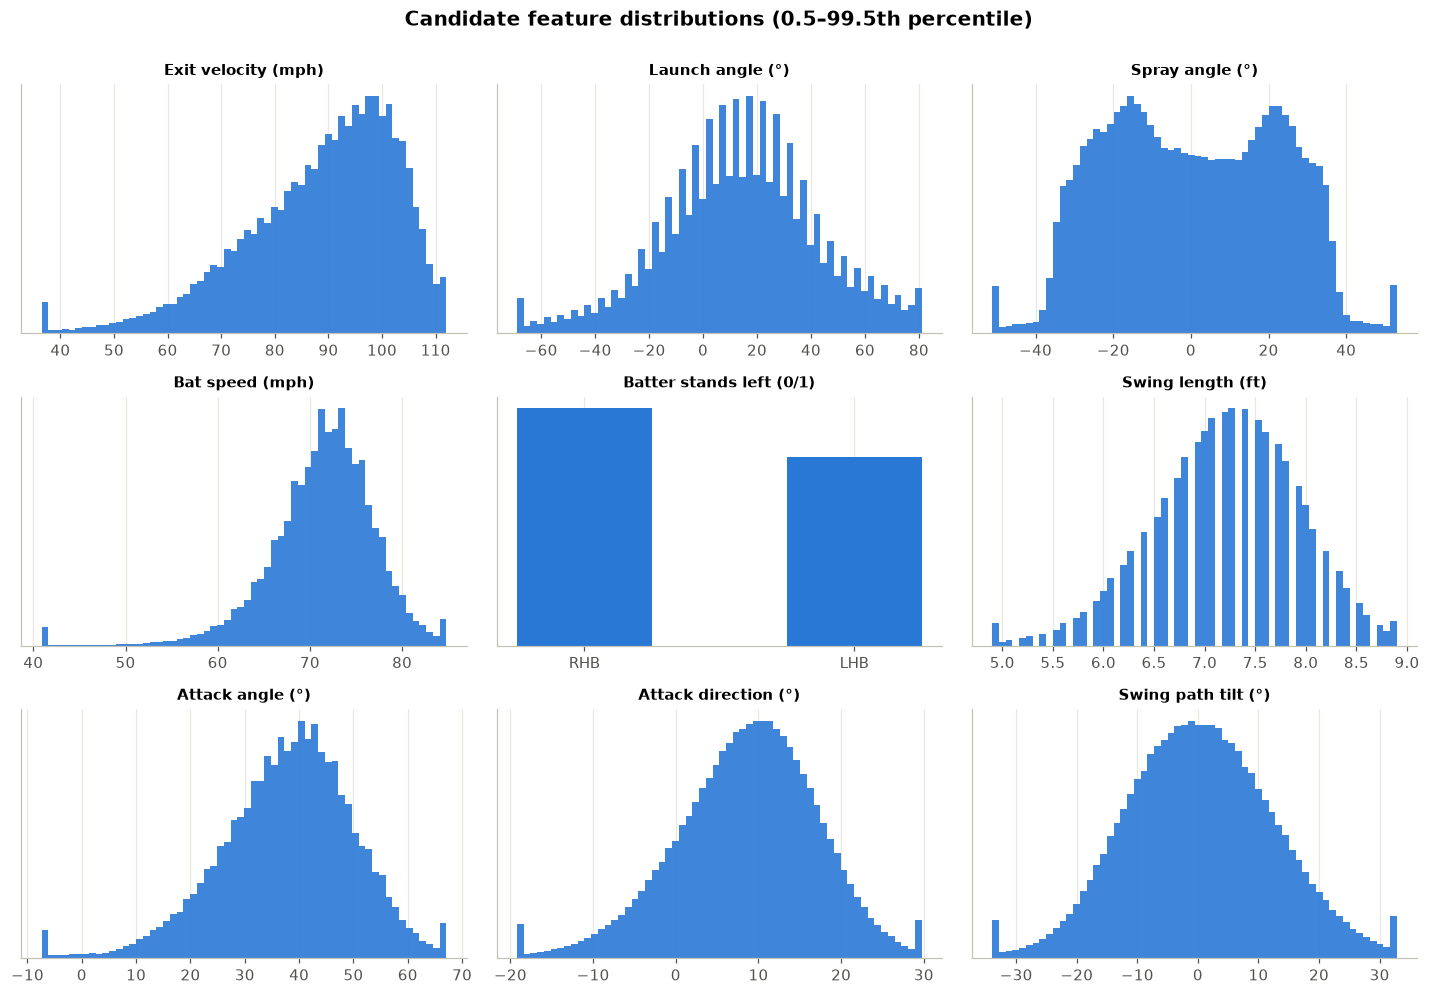

In [3]:
labels = {
    "launch_speed": "Exit velocity (mph)", "launch_angle": "Launch angle (°)",
    "spray_angle": "Spray angle (°)", "bat_speed": "Bat speed (mph)",
    "stand_L": "Batter stands left (0/1)", "swing_length": "Swing length (ft)",
    "attack_angle": "Attack angle (°)", "attack_direction": "Attack direction (°)",
    "swing_path_tilt": "Swing path tilt (°)",
}
fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for ax, f in zip(axes.flat, RAW_FEATURES):
    vals = df[f]
    if f == "stand_L":
        counts = vals.value_counts().sort_index()
        ax.bar(["RHB", "LHB"], counts.values, color=ACCENT, width=0.5)
    else:
        lo, hi = vals.quantile([0.005, 0.995])
        ax.hist(vals.clip(lo, hi), bins=60, color=ACCENT, alpha=0.9)
    ax.set_title(labels[f], fontsize=10)
    ax.set_yticks([])
fig.suptitle("Candidate feature distributions (0.5–99.5th percentile)", fontsize=13, fontweight="bold", y=1.0)
fig.tight_layout()
savefig(fig, "01_feature_distributions")
plt.show()

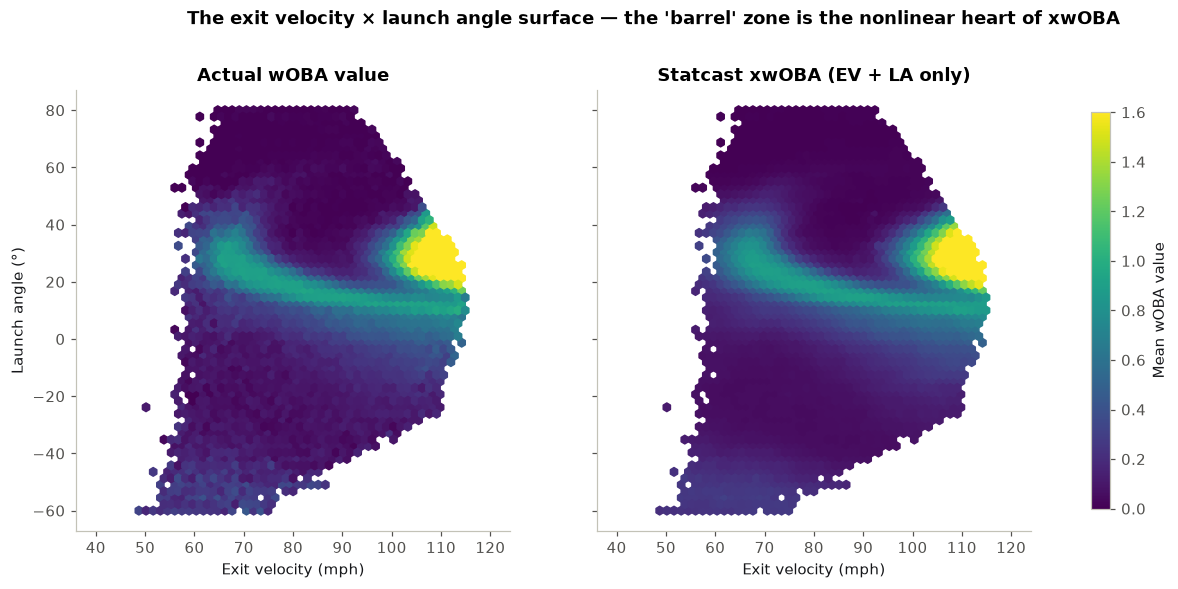

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True)
ext = (40, 120, -60, 80)
for ax, col, title in [
    (axes[0], "woba_value", "Actual wOBA value"),
    (axes[1], "estimated_woba_using_speedangle", "Statcast xwOBA (EV + LA only)"),
]:
    hb = ax.hexbin(df["launch_speed"], df["launch_angle"], C=df[col], reduce_C_function=np.mean,
                   gridsize=55, extent=ext, cmap="viridis", vmin=0, vmax=1.6, mincnt=25)
    ax.set_title(title)
    ax.set_xlabel("Exit velocity (mph)")
    ax.grid(False)
axes[0].set_ylabel("Launch angle (°)")
fig.colorbar(hb, ax=axes, label="Mean wOBA value", shrink=0.9)
fig.suptitle("The exit velocity × launch angle surface — the 'barrel' zone is the nonlinear heart of xwOBA",
             fontsize=12, fontweight="bold", y=1.02)
savefig(fig, "02_ev_la_surface")
plt.show()

The bright band around **95–115 mph at 20–35°** is the barrel zone. A 100 mph ball at 30° is usually a home run; the same exit velocity at 60° is a pop-up. That interaction is exactly what a linear model can't represent — which will matter in Part 1.

---
# Part 1 — Explanatory xwOBA

**Goal:** predict the actual wOBA value of each batted ball better than Statcast's own `estimated_woba_using_speedangle`.

**Method:** 80/20 random split (316,619 train / 79,155 test). For each model, forward and backward stepwise selection were run on a 50,000-row training subsample with 3-fold CV RMSE; whichever direction reached the lower CV RMSE defined that model's feature set. Each model was then refit on the full training set and scored once on the test set. XGBoost, LightGBM, and Random Forest were then hyperparameter-tuned with `RandomizedSearchCV` (5-fold CV).

### 1.1 Stepwise selection paths

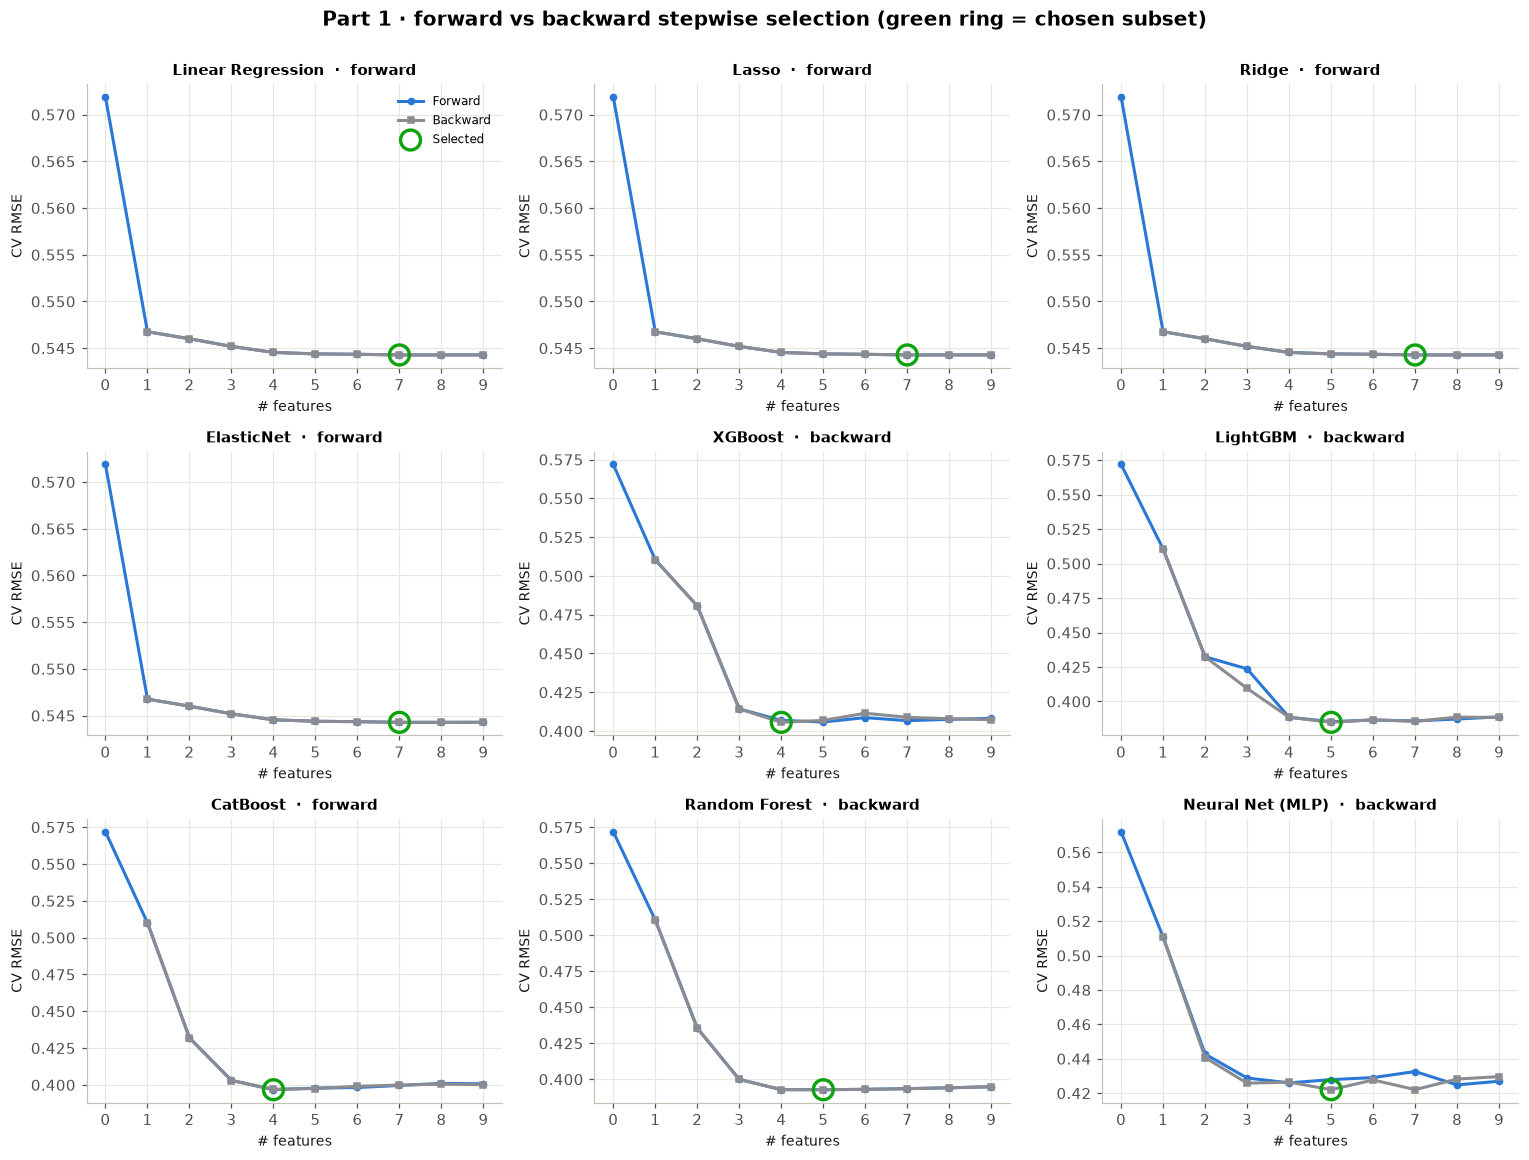

In [5]:
def plot_paths(sel, title, fname):
    fig, axes = plt.subplots(3, 3, figsize=(14, 10.5))
    for ax, (key, s) in zip(axes.flat, sel.items()):
        fw = [(len(p["features"]), p["cv_rmse"]) for p in s["forward"]]
        bw = [(len(p["features"]), p["cv_rmse"]) for p in s["backward"]]
        ax.plot(*zip(*fw), marker="o", ms=4, lw=2, color=ACCENT, label="Forward")
        ax.plot(*zip(*bw), marker="s", ms=4, lw=2, color=BENCH, label="Backward")
        best = s.get("selected_search_cv_rmse", s.get("selected_cv_rmse"))
        ax.scatter([len(s["selected_features"])], [best], s=170, facecolors="none",
                   edgecolors=GOOD, linewidths=2.2, zorder=5, label="Selected")
        ax.set_title(f"{NAMES[key]}  ·  {s['selected_direction']}", fontsize=10)
        ax.set_xticks(range(0, 10))
        ax.set_xlabel("# features", fontsize=9)
        ax.set_ylabel("CV RMSE", fontsize=9)
    axes.flat[0].legend(loc="upper right", fontsize=8)
    fig.suptitle(title, fontsize=13, fontweight="bold", y=1.0)
    fig.tight_layout()
    savefig(fig, fname)
    plt.show()

expl_sel = load("selection_paths.json")
plot_paths(expl_sel, "Part 1 · forward vs backward stepwise selection (green ring = chosen subset)",
           "03_explanatory_stepwise_paths")

Two patterns jump out:
- **Tree ensembles and the MLP flatten out after 4–5 features** — adding the remaining bat-tracking metrics slightly *hurts* CV RMSE.
- **Every linear model plateaus around 0.545**, far above the tree models at ~0.39. Feature choice can't fix a model that can't bend.

### 1.2 Model comparison vs. Statcast xwOBA

In [6]:
expl = load("model_results.json")
tuned = load("tuned_results.json")
tuned_rf = load("tuned_rf_results.json")
bench = expl["statcast_xwoba_benchmark"]

rows = []
for key, r in expl.items():
    if key == "statcast_xwoba_benchmark":
        continue
    rows.append({"key": key, "model": NAMES[key], "version": "stepwise", "features": r["selected_features"],
                 "rmse": r["test_rmse"], "mae": r["test_mae"], "r2": r["test_r2"], "corr": r["test_corr"]})
for key, src in [("xgboost", tuned["xgboost_tuned"]), ("lightgbm", tuned["lightgbm_tuned"]),
                 ("random_forest", tuned_rf["random_forest_tuned"])]:
    rows.append({"key": key, "model": NAMES[key], "version": "tuned", "features": src["features"],
                 "rmse": src["test_rmse"], "mae": src["test_mae"], "r2": src["test_r2"], "corr": src["test_corr"]})
rows.append({"key": "statcast", "model": "Statcast xwOBA", "version": "benchmark",
             "features": ["launch_speed", "launch_angle"], "rmse": bench["test_rmse"], "mae": bench["test_mae"],
             "r2": bench["test_r2"], "corr": bench["test_corr"]})

expl_df = pd.DataFrame(rows)
expl_df["rmse_vs_statcast"] = expl_df["rmse"] / bench["test_rmse"] - 1
expl_df["n_feat"] = expl_df["features"].str.len()
expl_df["features"] = expl_df["features"].apply(lambda f: ", ".join(f))
expl_df.sort_values("rmse")[["model", "version", "rmse", "mae", "r2", "corr", "rmse_vs_statcast", "n_feat", "features"]] \
    .style.format({"rmse": "{:.4f}", "mae": "{:.4f}", "r2": "{:.3f}", "corr": "{:.3f}", "rmse_vs_statcast": "{:+.1%}"}) \
    .hide(axis="index")

model,version,rmse,mae,r2,corr,rmse_vs_statcast,n_feat,features
LightGBM,tuned,0.3661,0.2392,0.591,0.769,-14.9%,5,"launch_speed, launch_angle, spray_angle, stand_L, swing_path_tilt"
Random Forest,tuned,0.3684,0.2399,0.586,0.766,-14.3%,5,"launch_speed, launch_angle, spray_angle, stand_L, swing_path_tilt"
Random Forest,stepwise,0.3721,0.2359,0.578,0.761,-13.5%,5,"launch_speed, launch_angle, spray_angle, stand_L, swing_path_tilt"
LightGBM,stepwise,0.3721,0.2553,0.578,0.761,-13.5%,5,"launch_speed, launch_angle, spray_angle, stand_L, swing_path_tilt"
XGBoost,tuned,0.3755,0.2593,0.570,0.756,-12.7%,4,"launch_speed, launch_angle, spray_angle, stand_L"
XGBoost,stepwise,0.3792,0.2667,0.562,0.750,-11.8%,4,"launch_speed, launch_angle, spray_angle, stand_L"
CatBoost,stepwise,0.3796,0.2687,0.561,0.749,-11.7%,4,"launch_angle, launch_speed, spray_angle, stand_L"
Neural Net (MLP),stepwise,0.3836,0.2692,0.551,0.743,-10.8%,5,"launch_speed, launch_angle, spray_angle, bat_speed, swing_path_tilt"
Statcast xwOBA,benchmark,0.4301,0.3015,0.436,0.660,+0.0%,2,"launch_speed, launch_angle"
Lasso,stepwise,0.5455,0.4644,0.093,0.305,+26.8%,7,"launch_speed, swing_path_tilt, bat_speed, launch_angle, spray_angle, swing_length, attack_direction"


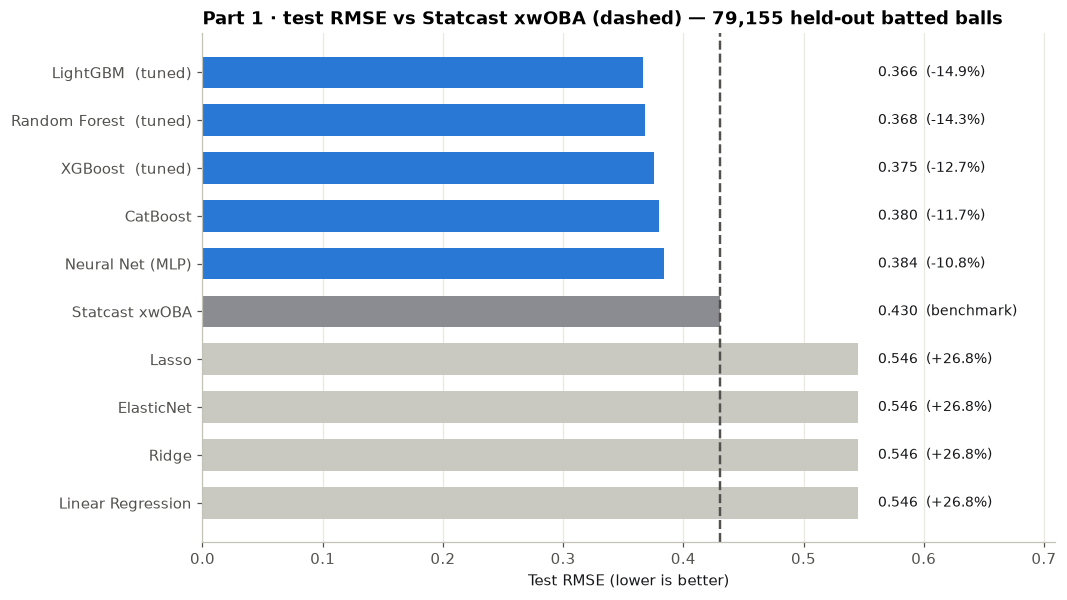

In [7]:
def best_per_model(frame):
    # tuned version wins where it exists; keep benchmark
    order = {"tuned": 0, "stepwise": 1, "benchmark": 2}
    return (frame.assign(o=frame["version"].map(order)).sort_values(["key", "o"])
                 .groupby("key", as_index=False).first().sort_values("rmse"))

def bar_compare(frame, bench_rmse, title, fname, xlabel="Test RMSE (lower is better)", fmt="{:.3f}"):
    frame = frame.sort_values("rmse", ascending=False)
    colors = [BENCH if v == "benchmark" else (ACCENT if r < bench_rmse else MUTED)
              for v, r in zip(frame["version"], frame["rmse"])]
    labels = [f"{m}{'  (tuned)' if v == 'tuned' else ''}" for m, v in zip(frame["model"], frame["version"])]
    fig, ax = plt.subplots(figsize=(10, 0.48 * len(frame) + 1.2))
    bars = ax.barh(labels, frame["rmse"], color=colors, height=0.66)
    ax.axvline(bench_rmse, ls="--", lw=1.6, color="#52514e")
    label_x = frame["rmse"].max() * 1.03
    ax.set_xlim(0, frame["rmse"].max() * 1.3)
    for b, r, v in zip(bars, frame["rmse"], frame["version"]):
        delta = r / bench_rmse - 1
        tag = "benchmark" if v == "benchmark" else f"{delta:+.1%}"
        ax.text(label_x, b.get_y() + b.get_height() / 2, f"{fmt.format(r)}  ({tag})",
                va="center", fontsize=9, color=INK)
    ax.set_xlabel(xlabel)
    ax.set_title(title, loc="left")
    ax.grid(axis="y", visible=False)
    savefig(fig, fname)
    plt.show()

expl_best = best_per_model(expl_df)
bar_compare(expl_best, bench["test_rmse"],
            "Part 1 · test RMSE vs Statcast xwOBA (dashed) — 79,155 held-out batted balls",
            "04_explanatory_model_comparison")

- **5 of 9 model families beat Statcast's xwOBA.** Tuned LightGBM is best: **RMSE 0.366 vs 0.430 (−14.9%)**, R² **0.591 vs 0.436**.
- All four linear variants (OLS/Ridge/Lasso/ElasticNet) converge to the same answer and do *worse* than Statcast — regularization doesn't help when the problem is nonlinearity, not overfitting.

### 1.3 Which features earned their place?

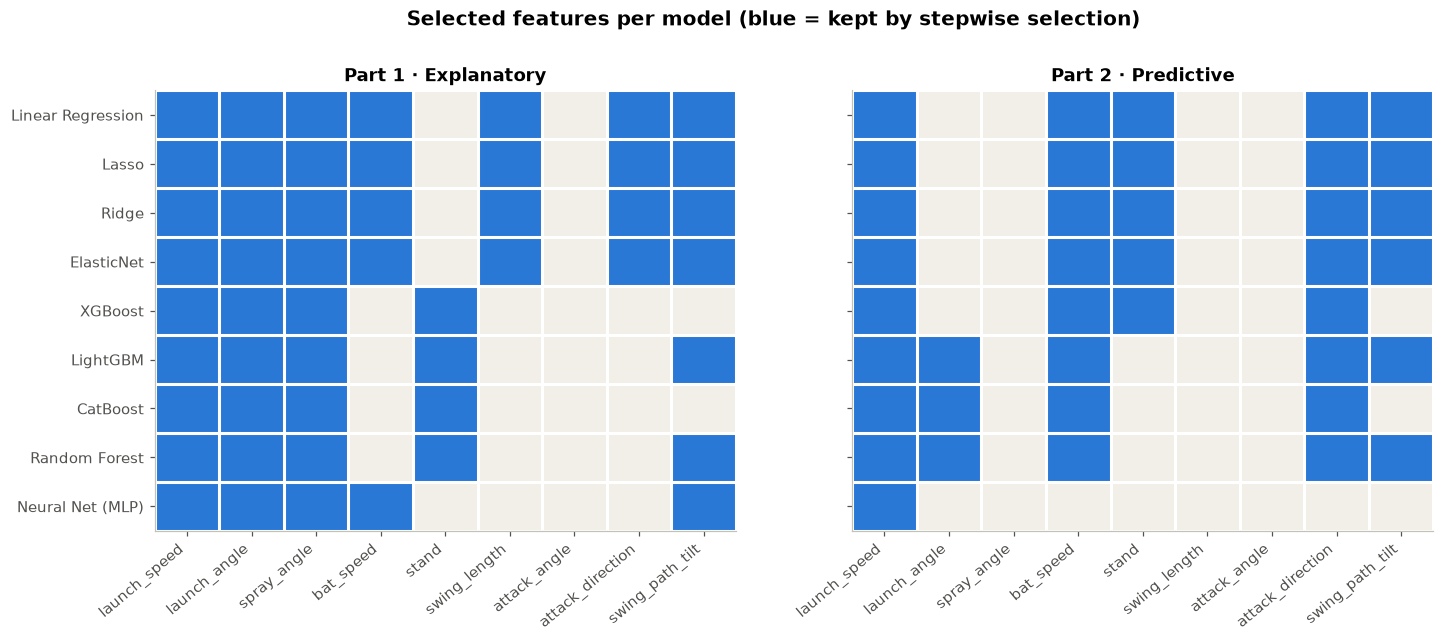

In [8]:
def selection_matrix(sel, strip=""):
    m = pd.DataFrame(0, index=[NAMES[k] for k in sel], columns=RAW_FEATURES)
    for k, s in sel.items():
        for f in s["selected_features"]:
            m.loc[NAMES[k], f.replace(strip, "") if strip else f] = 1
    return m

pred_sel = load("predictive_selection_paths.json")
m_expl = selection_matrix(expl_sel)
m_pred = selection_matrix(pred_sel, strip="_mean")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), sharey=True)
for ax, m, title in [(axes[0], m_expl, "Part 1 · Explanatory"), (axes[1], m_pred, "Part 2 · Predictive")]:
    ax.imshow(m.values, cmap=plt.matplotlib.colors.ListedColormap(["#f1efe8", ACCENT]), aspect="auto")
    ax.set_xticks(range(m.shape[1]), [c.replace("_L", "") for c in m.columns], rotation=40, ha="right")
    ax.set_yticks(range(m.shape[0]), m.index)
    ax.set_xticks(np.arange(-.5, m.shape[1]), minor=True)
    ax.set_yticks(np.arange(-.5, m.shape[0]), minor=True)
    ax.grid(which="minor", color="white", linewidth=2)
    ax.grid(which="major", visible=False)
    ax.tick_params(which="minor", length=0)
    ax.set_title(title)
fig.suptitle("Selected features per model (blue = kept by stepwise selection)", fontsize=13, fontweight="bold", y=1.02)
savefig(fig, "05_feature_selection_matrix")
plt.show()

**Explanatory:** exit velocity, launch angle, and spray angle were kept by **every** model. `attack_angle` was kept by **none**. Among the tree models, the only bat-tracking metric that survives is `swing_path_tilt` — bat speed adds little once you already know how hard and at what angle the ball came off the bat.

(The right panel is Part 2 — come back to it.)

### 1.4 Refit the winning model: tuned LightGBM

In [9]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=RNG)
lgb_cfg = tuned["lightgbm_tuned"]
LGB_FEATS = lgb_cfg["features"]
print("Features:", LGB_FEATS)
print("Params:  ", {k: round(v, 4) if isinstance(v, float) else v for k, v in lgb_cfg["best_params"].items()})

lgb_model = lgb.LGBMRegressor(**lgb_cfg["best_params"], random_state=RNG, n_jobs=-1, verbosity=-1)
lgb_model.fit(train_df[LGB_FEATS], train_df["woba_value"])
test_df = test_df.assign(custom_xwoba=lgb_model.predict(test_df[LGB_FEATS]))

pd.DataFrame({
    "Custom (tuned LightGBM)": metrics(test_df["woba_value"], test_df["custom_xwoba"]),
    "Statcast xwOBA": metrics(test_df["woba_value"], test_df["estimated_woba_using_speedangle"]),
}).T

Features: ['launch_speed', 'launch_angle', 'spray_angle', 'stand_L', 'swing_path_tilt']
Params:   {'colsample_bytree': 0.9331, 'learning_rate': 0.0586, 'max_depth': 12, 'min_child_samples': 7, 'n_estimators': 861, 'num_leaves': 67, 'reg_alpha': 7.5795, 'reg_lambda': 2.1368, 'subsample': 0.6849}


,rmse,mae,r2,corr,corr2
Custom (tuned LightGBM),0.3661,0.2392,0.5915,0.7691,0.5915
Statcast xwOBA,0.4301,0.3015,0.4361,0.6605,0.4362


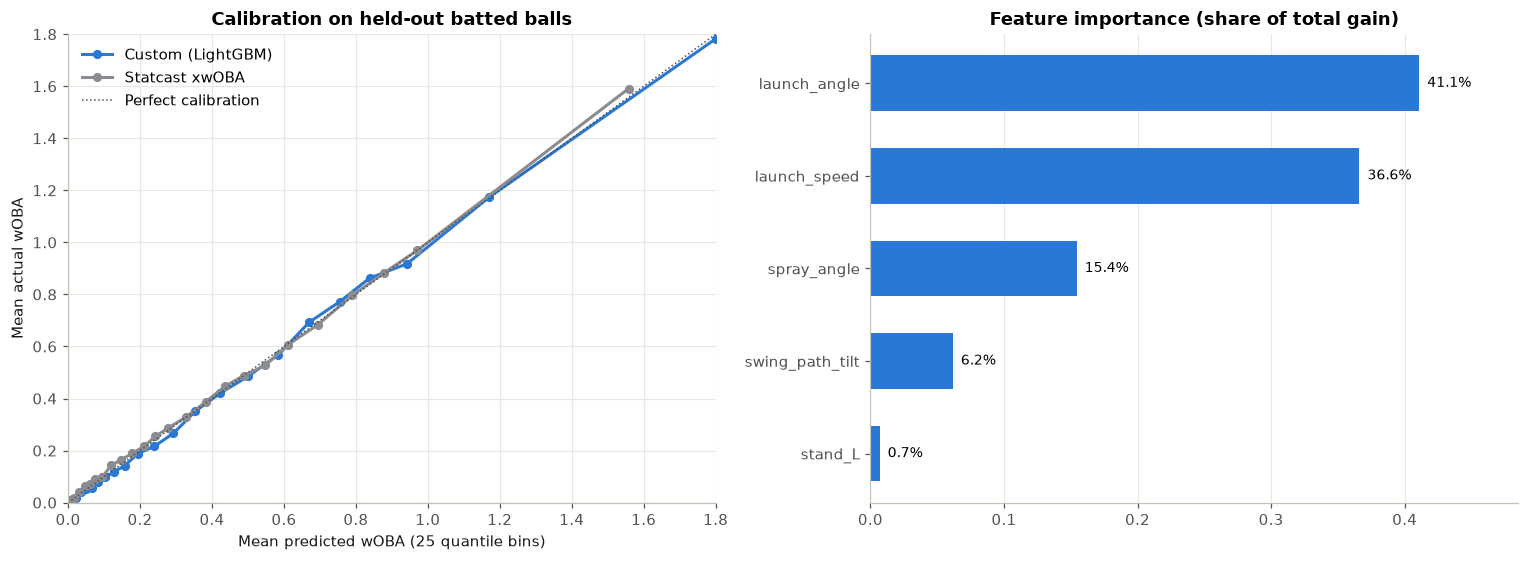

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

# Calibration: bin by each model's own prediction, compare to the actual outcome in that bin
ax = axes[0]
for col, color, label in [("custom_xwoba", ACCENT, "Custom (LightGBM)"),
                          ("estimated_woba_using_speedangle", BENCH, "Statcast xwOBA")]:
    bins = pd.qcut(test_df[col], 25, duplicates="drop")
    g = test_df.groupby(bins, observed=True).agg(pred=(col, "mean"), actual=("woba_value", "mean"))
    ax.plot(g["pred"], g["actual"], marker="o", ms=5, lw=2, color=color, label=label)
lim = [0, 1.8]
ax.plot(lim, lim, ls=":", color="#52514e", lw=1, label="Perfect calibration")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Mean predicted wOBA (25 quantile bins)")
ax.set_ylabel("Mean actual wOBA")
ax.set_title("Calibration on held-out batted balls")
ax.legend(loc="upper left")

# Feature importance (gain)
ax = axes[1]
imp = pd.Series(lgb_model.booster_.feature_importance("gain"), index=LGB_FEATS)
imp = (imp / imp.sum()).sort_values()
ax.barh(imp.index, imp.values, color=ACCENT, height=0.6)
for i, v in enumerate(imp.values):
    ax.text(v, i, f"  {v:.1%}", va="center", fontsize=9)
ax.set_xlim(0, imp.max() * 1.18)
ax.set_title("Feature importance (share of total gain)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
savefig(fig, "06_explanatory_calibration_importance")
plt.show()

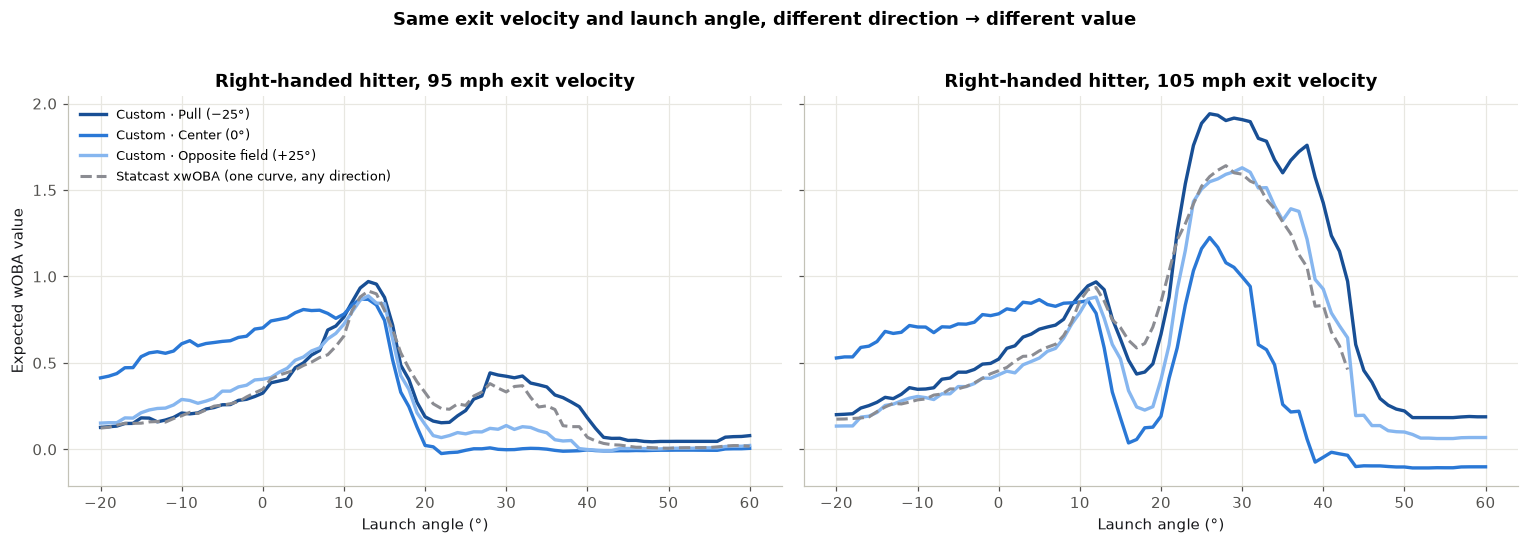

In [11]:
# What the custom model sees that Statcast can't: spray direction.
la = np.arange(-20, 61, 1)
tilt = df["swing_path_tilt"].median()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, ev in zip(axes, [95, 105]):
    for spray, color, label in [(-25, ACCENT_DARK, "Pull (−25°)"), (0, ACCENT, "Center (0°)"),
                                (25, "#86b6ef", "Opposite field (+25°)")]:
        grid = pd.DataFrame({"launch_speed": ev, "launch_angle": la, "spray_angle": spray,
                             "stand_L": 0.0, "swing_path_tilt": tilt})[LGB_FEATS]
        ax.plot(la, lgb_model.predict(grid), lw=2.2, color=color, label=f"Custom · {label}")
    near = test_df[(test_df["launch_speed"].between(ev - 1.5, ev + 1.5))]
    sc = near.groupby(near["launch_angle"].round()).agg(x=("estimated_woba_using_speedangle", "mean"),
                                                        n=("woba_value", "size"))
    sc = sc[(sc["n"] >= 15) & sc.index.isin(la)]
    ax.plot(sc.index, sc["x"], ls="--", lw=2, color=BENCH, label="Statcast xwOBA (one curve, any direction)")
    ax.set_title(f"Right-handed hitter, {ev} mph exit velocity")
    ax.set_xlabel("Launch angle (°)")
axes[0].set_ylabel("Expected wOBA value")
axes[0].legend(loc="upper left", fontsize=8.5)
fig.suptitle("Same exit velocity and launch angle, different direction → different value",
             fontsize=12, fontweight="bold", y=1.02)
fig.tight_layout()
savefig(fig, "07_spray_angle_effect")
plt.show()

Statcast's xwOBA assigns one value to every (EV, LA) pair regardless of direction. The custom model learns that a **pulled** fly ball at 95 mph is worth far more than the same ball hit to the opposite field (shorter fences, pull-side carry) — a large part of its edge over Statcast comes from that. (Dead center is the deepest part of the park, so center-field fly balls are worth the least; ground balls up the middle find holes more often, which is why the center line runs highest at negative launch angles.)

### 1.5 The catch: does it hold up next year?

A better fit to *this* season isn't automatically a better measure of *skill*. For every batter with ≥100 batted balls in two consecutive seasons, compare each metric in season N to the **same metric** in season N+1. A metric that captures more true talent should correlate more strongly with itself.

In [12]:
season = pd.read_csv(RESULTS / "batter_xwoba_by_season.csv")
MIN_BBE = 100
pairs = [(2023, 2024), (2024, 2025), (2025, 2026)]
stack = []
for y1, y2 in pairs:
    a = season[(season.season == y1) & (season.n_bbe >= MIN_BBE)]
    b = season[(season.season == y2) & (season.n_bbe >= MIN_BBE)]
    stack.append(a.merge(b, on="batter", suffixes=("_n", "_n1")).assign(pair=f"{y1}→{y2}"))
yoy = pd.concat(stack, ignore_index=True)

stab_metrics = [("statcast_xwobacon", "Statcast xwOBAcon", BENCH),
                ("custom_xwobacon", "Custom xwOBAcon (LightGBM)", ACCENT),
                ("actual_wobacon", "Actual wOBAcon", MUTED)]

table = {}
for p, g in list(yoy.groupby("pair")) + [("Pooled", yoy)]:
    table[p] = {"n": len(g), **{lbl: pearsonr(g[f"{c}_n"], g[f"{c}_n1"])[0] for c, lbl, _ in stab_metrics}}
pd.DataFrame(table).T

,n,Statcast xwOBAcon,Custom xwOBAcon (LightGBM),Actual wOBAcon
2023→2024,215.0000,0.7261,0.6080,0.4247
2024→2025,296.0000,0.7614,0.6779,0.5514
2025→2026,288.0000,0.7515,0.6691,0.4902
Pooled,799.0000,0.7480,0.6404,0.4853


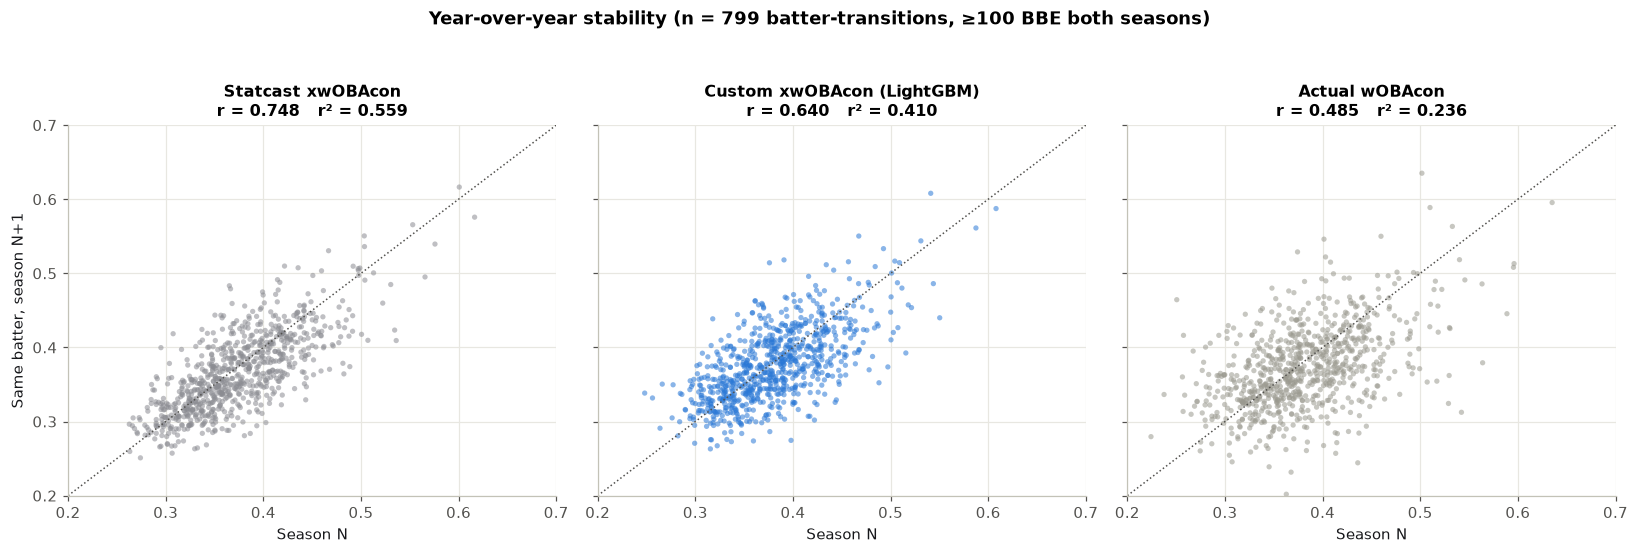

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharex=True, sharey=True)
for ax, (c, lbl, color) in zip(axes, stab_metrics):
    x, y = yoy[f"{c}_n"], yoy[f"{c}_n1"]
    r = pearsonr(x, y)[0]
    ax.scatter(x, y, s=12, alpha=0.55, color=color if color != MUTED else "#9a998f", edgecolors="none")
    ax.plot([0.2, 0.7], [0.2, 0.7], ls=":", color="#52514e", lw=1)
    ax.set_title(f"{lbl}\nr = {r:.3f}   r² = {r*r:.3f}", fontsize=10.5)
    ax.set_xlabel("Season N")
axes[0].set_ylabel("Same batter, season N+1")
axes[0].set_xlim(0.2, 0.7); axes[0].set_ylim(0.2, 0.7)
fig.suptitle(f"Year-over-year stability (n = {len(yoy)} batter-transitions, ≥{MIN_BBE} BBE both seasons)",
             fontsize=12, fontweight="bold", y=1.04)
fig.tight_layout()
savefig(fig, "08_yoy_stability")
plt.show()

**Statcast's simpler xwOBAcon is the *stickier* metric** (r = 0.748 vs 0.640). The custom model explains this season better, but some of what `spray_angle`, `stand`, and `swing_path_tilt` capture is season-specific noise that doesn't persist. Both expected stats beat raw outcomes (r = 0.485), so modeling contact quality does filter out luck.

That motivates Part 2: instead of hoping an explanatory model happens to be predictive, **train one to predict next season directly.**

---
# Part 2 — Predictive xwOBAcon

**Goal:** forecast each batter's **actual wOBAcon next season** better than simply carrying forward his Statcast xwOBAcon.

**Method:**
- One row per batter-season transition. Features = the batter's **season-N mean** of each of the 9 candidates. Target = his **actual wOBAcon in season N+1**. Both seasons require ≥100 batted balls.
- **Temporal split** (a real forecasting test): train on 2023→24 and 2024→25 (511 rows), test on 2025→26 (288 rows).
- Same 9 model families, same forward/backward stepwise selection (5-fold CV), with shallow, regularized hyperparameters appropriate for ~500 rows. XGBoost was then tuned with a 3,000-config random search (10-fold CV).

In [14]:
pdata = pd.read_csv(DATA / "predictive_dataset.csv")
TARGET = "target_next_actual_wobacon"
ptrain = pdata[pdata["pair"].isin(["2023->2024", "2024->2025"])].reset_index(drop=True)
ptest = pdata[pdata["pair"] == "2025->2026"].reset_index(drop=True)
print(f"Train: {len(ptrain)} transitions  |  Test (held out, later): {len(ptest)} transitions")
pdata.groupby("pair").size().rename("batters")

Train: 511 transitions  |  Test (held out, later): 288 transitions


pair
2023->2024    215
2024->2025    296
2025->2026    288
Name: batters, dtype: int64

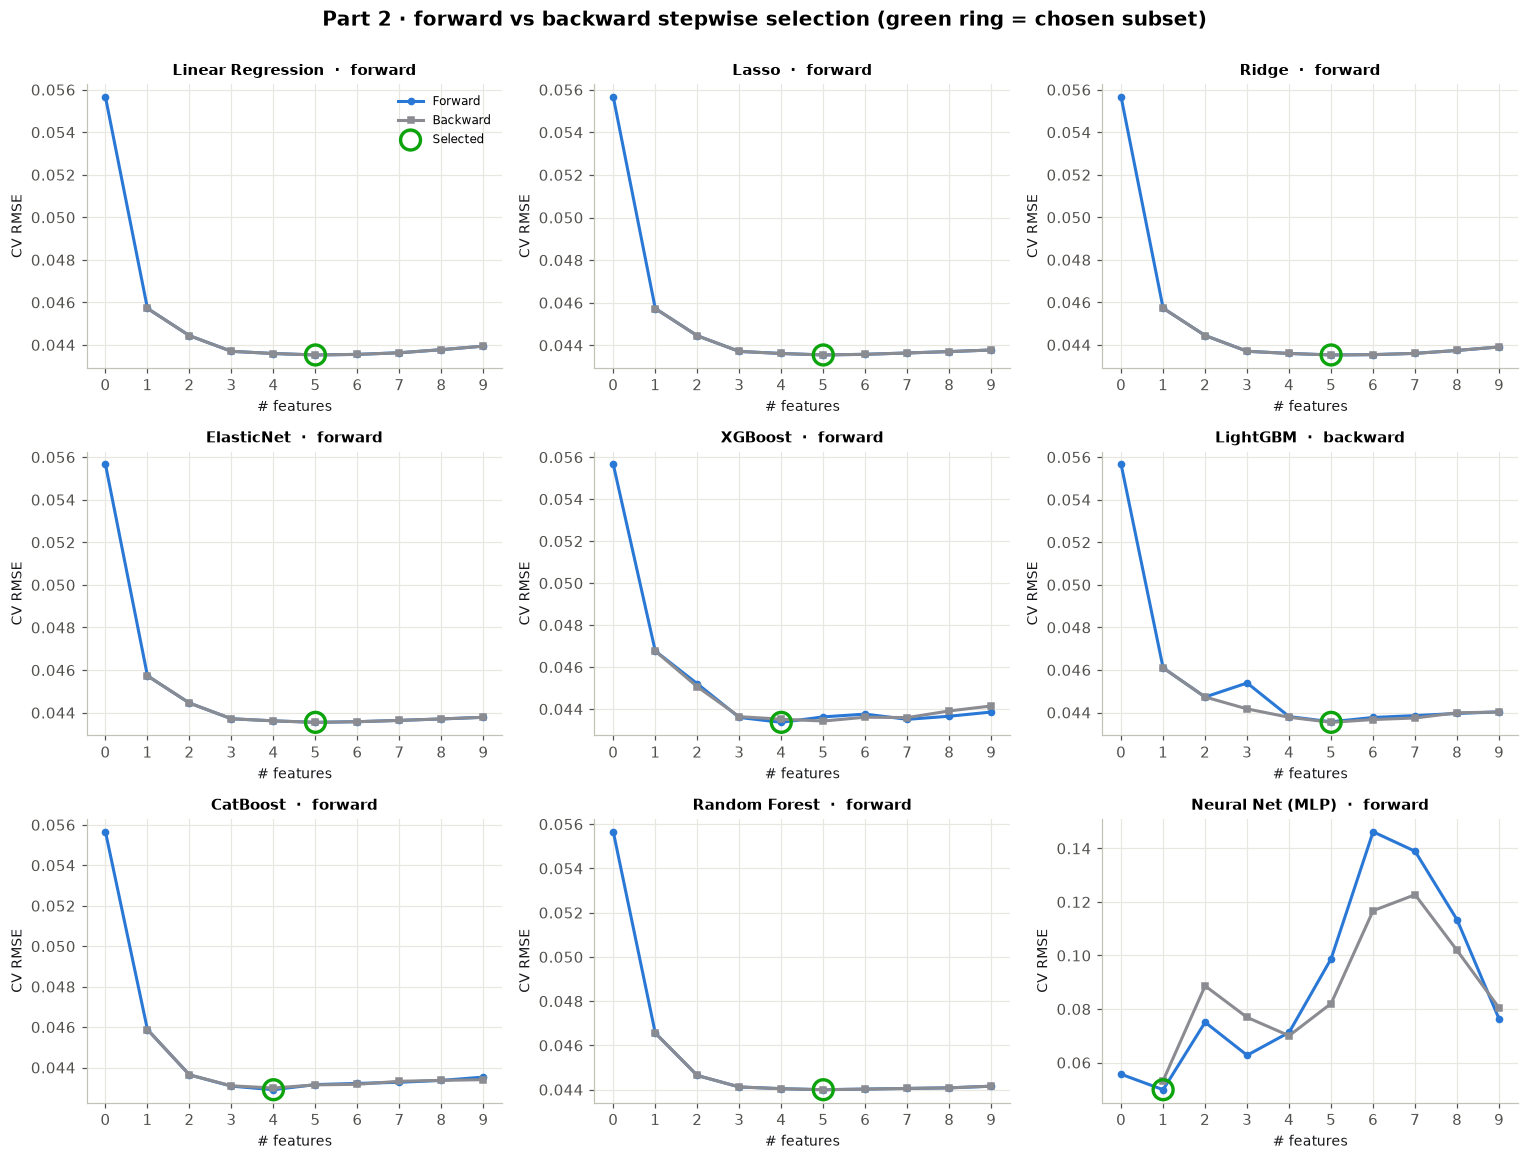

In [15]:
plot_paths(pred_sel, "Part 2 · forward vs backward stepwise selection (green ring = chosen subset)",
           "09_predictive_stepwise_paths")

The paths are much flatter and noisier than Part 1 — with ~400 rows per CV fold, most feature subsets land within a few thousandths of each other. The MLP is the outlier: its CV error swings wildly as features are added, a classic sign of a neural net starved for data.

### 2.1 Same features, a completely different pecking order

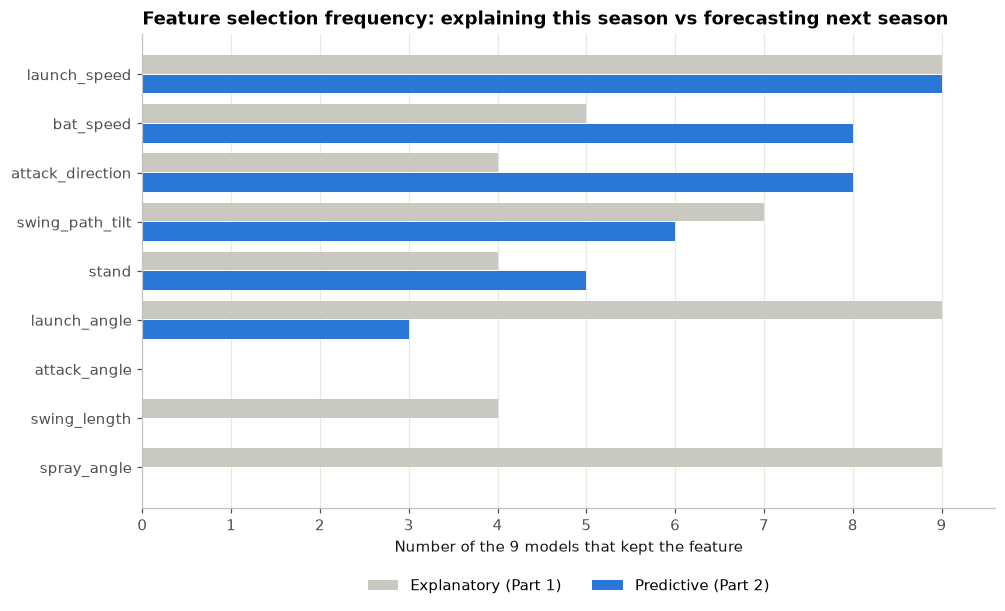

,launch_speed,bat_speed,attack_direction,swing_path_tilt,stand,launch_angle,spray_angle,swing_length,attack_angle
Explanatory (Part 1),9,5,4,7,4,9,9,4,0
Predictive (Part 2),9,8,8,6,5,3,0,0,0


In [16]:
freq = pd.DataFrame({"Explanatory (Part 1)": m_expl.sum(), "Predictive (Part 2)": m_pred.sum()})
freq.index = [i.replace("_L", "") for i in freq.index]
freq = freq.sort_values("Predictive (Part 2)")

fig, ax = plt.subplots(figsize=(10, 5.6))
y = np.arange(len(freq))
ax.barh(y + 0.2, freq["Explanatory (Part 1)"], height=0.38, color=MUTED, label="Explanatory (Part 1)")
ax.barh(y - 0.2, freq["Predictive (Part 2)"], height=0.38, color=ACCENT, label="Predictive (Part 2)")
ax.set_yticks(y, freq.index)
ax.set_xlim(0, 9.6)
ax.set_xticks(range(0, 10))
ax.set_xlabel("Number of the 9 models that kept the feature")
ax.set_title("Feature selection frequency: explaining this season vs forecasting next season", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
ax.grid(axis="y", visible=False)
savefig(fig, "10_feature_frequency_explanatory_vs_predictive")
plt.show()
freq.sort_values("Predictive (Part 2)", ascending=False).T

This is the most interesting result in the project:

- **`bat_speed` and `attack_direction`** go from marginal in the explanatory model to kept by **8 of 9** predictive models.
- **`spray_angle`** — kept by all 9 explanatory models — is kept by **none** of the predictive ones. `launch_angle` drops from 9/9 to 3/9.
- **`launch_speed`** matters in both.

Swing mechanics (how fast and in what direction a hitter swings) are a **stable physical skill**. The precise launch angle and direction of this season's batted balls are highly informative about *what happened* but much noisier about *what happens next*.

### 2.2 Model comparison vs. Statcast's naive projection

In [17]:
pres = load("predictive_model_results.json")
ptuned = load("tuned_predictive_xgboost_results.json")["predictive_xgboost_tuned_fixed_features"]

rows = []
for key, r in pres.items():
    if key == "statcast_xwobacon_naive":
        name, version = "Statcast xwOBAcon (naive)", "benchmark"
    elif key == "custom_explanatory_naive":
        name, version = "Part 1 custom xwOBAcon (naive)", "naive"
    else:
        name, version = NAMES[key], "stepwise"
    rows.append({"key": key, "model": name, "version": version, "features": r["selected_features"],
                 "rmse": r["test_rmse"], "mae": r["test_mae"], "r2": r["test_r2"], "corr": r["test_corr"]})
rows.append({"key": "xgboost", "model": "XGBoost", "version": "tuned", "features": ptuned["features"],
             "rmse": ptuned["test_rmse"], "mae": ptuned["test_mae"], "r2": ptuned["test_r2"], "corr": ptuned["test_corr"]})

pred_df = pd.DataFrame(rows)
pbench = pres["statcast_xwobacon_naive"]["test_rmse"]
pred_df["rmse_vs_statcast"] = pred_df["rmse"] / pbench - 1
pred_df["corr2"] = pred_df["corr"] ** 2
pred_df["n_feat"] = pred_df["features"].str.len()
pred_df["features"] = pred_df["features"].apply(lambda f: ", ".join(x.replace("_mean", "") for x in f))
pred_df.sort_values("rmse")[["model", "version", "rmse", "mae", "r2", "corr", "corr2", "rmse_vs_statcast", "n_feat", "features"]] \
    .style.format({"rmse": "{:.4f}", "mae": "{:.4f}", "r2": "{:.3f}", "corr": "{:.3f}", "corr2": "{:.3f}",
                   "rmse_vs_statcast": "{:+.1%}"}).hide(axis="index")

model,version,rmse,mae,r2,corr,corr2,rmse_vs_statcast,n_feat,features
XGBoost,tuned,0.0420,0.0335,0.399,0.637,0.405,-12.0%,4,"bat_speed, attack_direction, launch_speed, launch_angle"
XGBoost,stepwise,0.0421,0.0336,0.394,0.635,0.403,-11.6%,4,"bat_speed, launch_speed, attack_direction, stand_L"
CatBoost,stepwise,0.0425,0.0336,0.385,0.625,0.390,-10.9%,4,"bat_speed, attack_direction, launch_speed, launch_angle"
Random Forest,stepwise,0.0426,0.0339,0.382,0.624,0.389,-10.7%,5,"bat_speed, attack_direction, launch_speed, launch_angle, swing_path_tilt"
LightGBM,stepwise,0.0429,0.0341,0.372,0.617,0.381,-10.0%,5,"launch_speed, launch_angle, bat_speed, attack_direction, swing_path_tilt"
ElasticNet,stepwise,0.0435,0.0354,0.355,0.602,0.362,-8.8%,5,"bat_speed, attack_direction, launch_speed, stand_L, swing_path_tilt"
Lasso,stepwise,0.0435,0.0354,0.355,0.602,0.362,-8.8%,5,"bat_speed, attack_direction, launch_speed, stand_L, swing_path_tilt"
Ridge,stepwise,0.0435,0.0354,0.353,0.602,0.362,-8.7%,5,"bat_speed, attack_direction, launch_speed, stand_L, swing_path_tilt"
Linear Regression,stepwise,0.0436,0.0354,0.353,0.602,0.363,-8.6%,5,"bat_speed, attack_direction, launch_speed, stand_L, swing_path_tilt"
Neural Net (MLP),stepwise,0.0476,0.0374,0.228,0.512,0.263,-0.2%,1,launch_speed


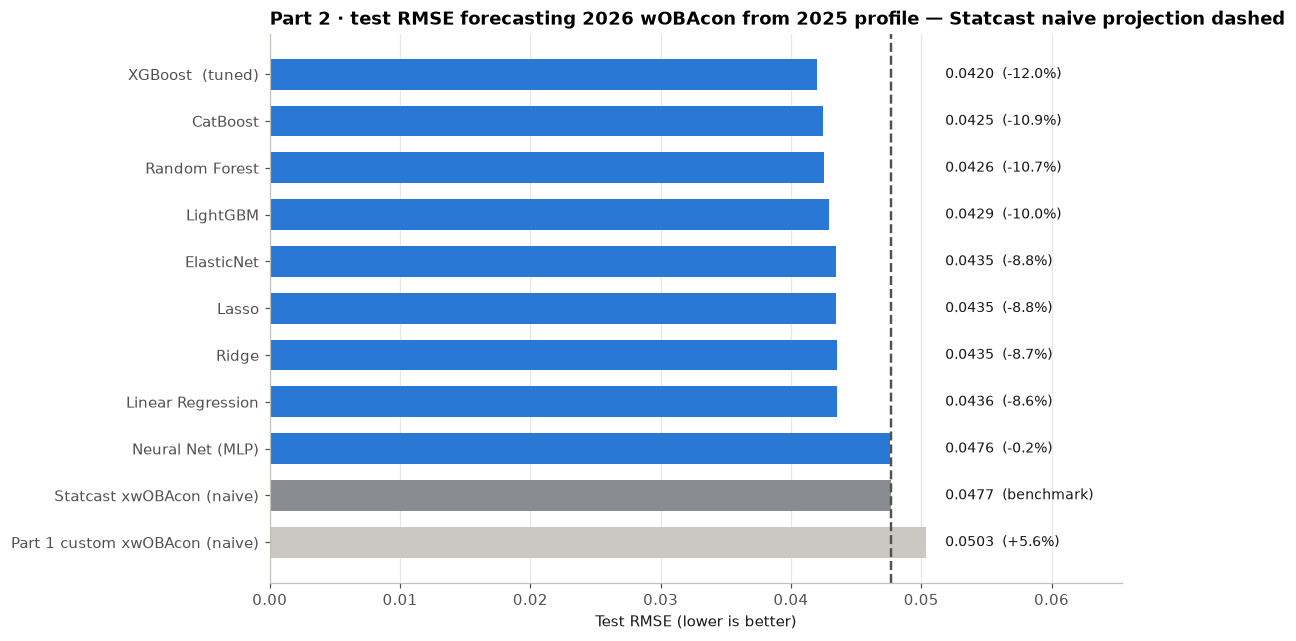

In [18]:
pred_best = best_per_model(pred_df.assign(version=pred_df["version"].replace({"naive": "stepwise"})))
pred_best.loc[pred_best["key"] == "custom_explanatory_naive", "version"] = "naive"
bar_compare(pred_best, pbench,
            "Part 2 · test RMSE forecasting 2026 wOBAcon from 2025 profile — Statcast naive projection dashed",
            "11_predictive_model_comparison", fmt="{:.4f}")

- **8 of 9 model families beat Statcast's naive projection; the MLP ties it.** Tuned XGBoost is best: **RMSE 0.0420 vs 0.0477 (−12.0%)**, R² **0.399 vs 0.225**.
- Reusing the **Part 1 explanatory model** as a forecast is *worse* than Statcast (RMSE 0.0503) — confirming the stability check: a model built to explain is not automatically good at forecasting.

**A note on R² vs corr²:** the naive benchmarks are raw, un-recalibrated numbers used as forecasts, so R² (which penalizes scale/bias mismatch) is much lower than their squared correlation (Statcast: R² 0.225 vs corr² 0.354). Fitted models are optimized for exactly what R² measures, so their two numbers stay close. Even on corr² alone, tuned XGBoost (0.405) beats Statcast (0.354).

### 2.3 Refit the winning model: tuned XGBoost

In [19]:
XGB_FEATS = ptuned["features"]
print("Features:", XGB_FEATS)
print("Params:  ", {k: round(v, 4) if isinstance(v, float) else v for k, v in ptuned["best_params"].items()})

xgb_model = xgb.XGBRegressor(**ptuned["best_params"], random_state=RNG, n_jobs=1, tree_method="hist", verbosity=0)
xgb_model.fit(ptrain[XGB_FEATS].values, ptrain[TARGET].values)
ptest = ptest.assign(pred_xgb=xgb_model.predict(ptest[XGB_FEATS].values))

pd.DataFrame({
    "Tuned XGBoost (predictive)": metrics(ptest[TARGET], ptest["pred_xgb"]),
    "Statcast xwOBAcon, naive": metrics(ptest[TARGET], ptest["statcast_xwobacon"]),
    "Part 1 custom xwOBAcon, naive": metrics(ptest[TARGET], ptest["custom_xwobacon"]),
}).T

Features: ['bat_speed_mean', 'attack_direction_mean', 'launch_speed_mean', 'launch_angle_mean']
Params:   {'colsample_bytree': 0.6042, 'gamma': 0.0161, 'learning_rate': 0.0322, 'max_depth': 4, 'min_child_weight': 2, 'n_estimators': 578, 'reg_alpha': 0.0093, 'reg_lambda': 4.3563, 'subsample': 0.5967}


,rmse,mae,r2,corr,corr2
Tuned XGBoost (predictive),0.0420,0.0335,0.3993,0.6367,0.4054
"Statcast xwOBAcon, naive",0.0477,0.0386,0.2249,0.5955,0.3546
"Part 1 custom xwOBAcon, naive",0.0503,0.0402,0.1360,0.5574,0.3107


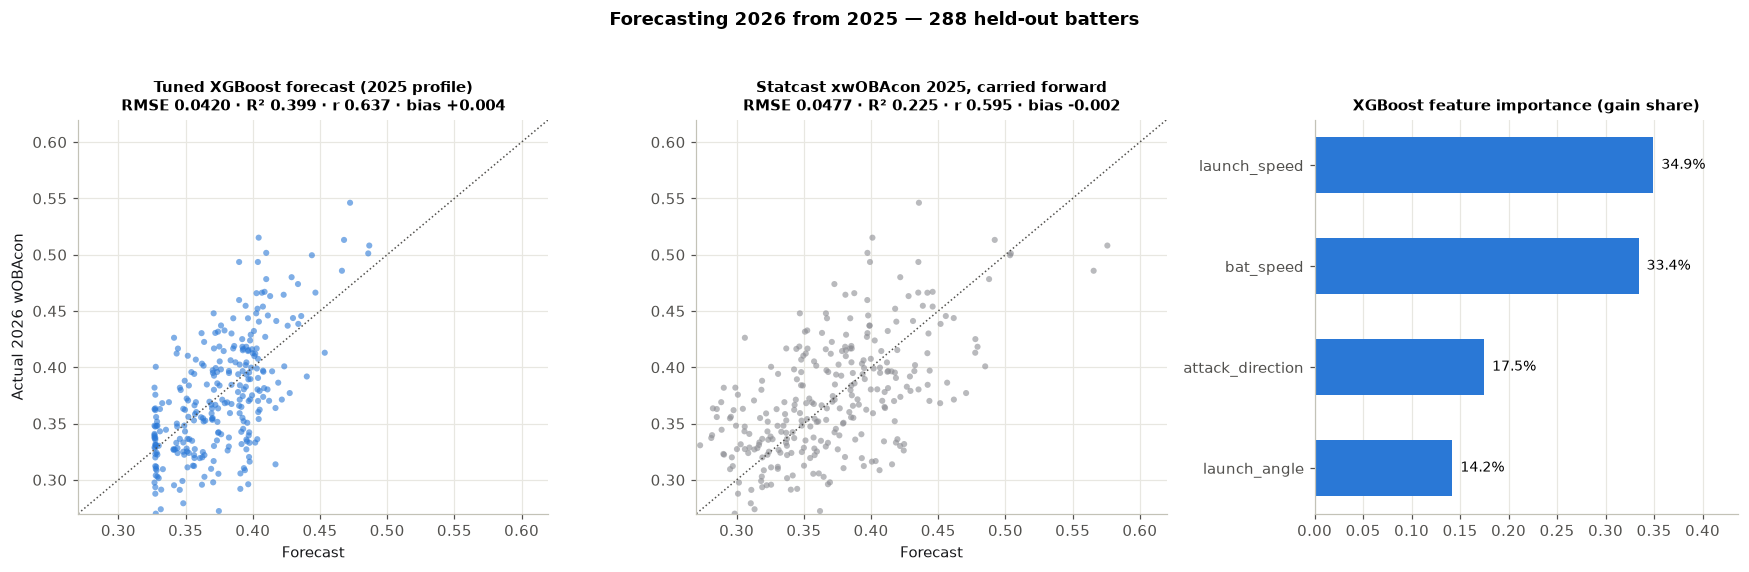

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), gridspec_kw={"width_ratios": [1, 1, 0.9]})
lim = (0.27, 0.62)
for ax, col, color, title in [
    (axes[0], "pred_xgb", ACCENT, "Tuned XGBoost forecast (2025 profile)"),
    (axes[1], "statcast_xwobacon", BENCH, "Statcast xwOBAcon 2025, carried forward"),
]:
    m = metrics(ptest[TARGET], ptest[col])
    ax.scatter(ptest[col], ptest[TARGET], s=16, alpha=0.6, color=color, edgecolors="none")
    ax.plot(lim, lim, ls=":", color="#52514e", lw=1)
    bias = (ptest[col] - ptest[TARGET]).mean()
    ax.set_title(f"{title}\nRMSE {m['rmse']:.4f} · R² {m['r2']:.3f} · r {m['corr']:.3f} · bias {bias:+.3f}",
                 fontsize=10)
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel("Forecast")
axes[0].set_ylabel("Actual 2026 wOBAcon")

ax = axes[2]
imp = pd.Series(xgb_model.get_booster().get_score(importance_type="gain"))
imp.index = [XGB_FEATS[int(i[1:])].replace("_mean", "") for i in imp.index]
imp = (imp / imp.sum()).sort_values()
ax.barh(imp.index, imp.values, color=ACCENT, height=0.55)
for i, v in enumerate(imp.values):
    ax.text(v, i, f"  {v:.1%}", va="center", fontsize=9)
ax.set_xlim(0, imp.max() * 1.25)
ax.set_title("XGBoost feature importance (gain share)", fontsize=10)
ax.grid(axis="y", visible=False)
fig.suptitle(f"Forecasting 2026 from 2025 — {len(ptest)} held-out batters", fontsize=12, fontweight="bold", y=1.03)
fig.tight_layout()
savefig(fig, "12_predictive_forecast_vs_actual")
plt.show()

Both forecasts are nearly unbiased on average (bias within ±0.004). The difference is **spread**: Statcast's carried-forward xwOBAcon spreads hitters out more than their next-season outcomes do, so its extreme values overshoot. The XGBoost forecast shrinks extreme hitters toward the mean, which is the regression to the mean a good projection should apply. That over-dispersion is why Statcast's R² (0.225) falls so far below its corr² (0.354).

### 2.4 Leaderboards

Explanatory (what each hitter's contact *was worth*) and predictive (what the prior season's swing profile *forecast*), 2026, min. 100 batted balls.

> The predictive leaderboard comes from `src/predictive_xwoba_by_season.py`, which refits the tuned XGBoost on **all** 799 transitions for production use — so these forecasts are in-sample and slightly optimistic relative to the held-out numbers above.

In [21]:
expl_lb = (season[(season.season == 2026) & (season.n_bbe >= 100)]
           .sort_values("custom_xwobacon", ascending=False)
           .head(15)[["player_name", "n_bbe", "custom_xwobacon", "statcast_xwobacon", "actual_wobacon"]])
expl_lb.index = range(1, len(expl_lb) + 1)
print("Explanatory xwOBAcon, 2026 (tuned LightGBM)")
expl_lb

Explanatory xwOBAcon, 2026 (tuned LightGBM)


,player_name,n_bbe,custom_xwobacon,statcast_xwobacon,actual_wobacon
1,"Judge, Aaron",135,0.5612,0.5395,0.5081
2,"Valdez, Esmerlyn",130,0.5379,0.4869,0.5731
3,"Wood, James",295,0.5165,0.5505,0.4995
4,"Schwarber, Kyle",314,0.5144,0.4908,0.5011
5,"Alvarez, Yordan",395,0.5142,0.5098,0.4800
6,"Cruz, Oneil",178,0.4959,0.5075,0.5461
7,"Alonso, Pete",379,0.4878,0.4767,0.4437
8,"Ohtani, Shohei",353,0.4861,0.4951,0.4857
9,"Goodman, Hunter",279,0.4765,0.4345,0.5016
10,"Bauers, Jake",285,0.4718,0.4477,0.4663


In [22]:
pred_lb = pd.read_csv(RESULTS / "predictive_xwoba_by_season.csv")
pred_lb = (pred_lb[(pred_lb.season == 2026) & (pred_lb.n_bbe >= 100)]
           .sort_values("predictive_xwobacon", ascending=False)
           .head(15)[["player_name", "n_bbe", "predictive_xwobacon", "statcast_xwobacon", "actual_wobacon"]])
pred_lb.index = range(1, len(pred_lb) + 1)
print("Predictive xwOBAcon for 2026, forecast from each hitter's 2025 profile (tuned XGBoost)")
pred_lb

Predictive xwOBAcon for 2026, forecast from each hitter's 2025 profile (tuned XGBoost)


,player_name,n_bbe,predictive_xwobacon,statcast_xwobacon,actual_wobacon
1,"Schwarber, Kyle",314,0.5061,0.4908,0.5011
2,"Judge, Aaron",135,0.4895,0.5395,0.5081
3,"Ohtani, Shohei",353,0.4810,0.4951,0.4857
4,"Cruz, Oneil",178,0.4809,0.5075,0.5461
5,"Wood, James",295,0.4704,0.5505,0.4995
6,"Kurtz, Nick",187,0.4631,0.5096,0.5131
7,"Alvarez, Yordan",395,0.4541,0.5098,0.4800
8,"Acuña Jr., Ronald",251,0.4467,0.4283,0.4129
9,"Bauers, Jake",285,0.4387,0.4477,0.4663
10,"Alonso, Pete",379,0.4368,0.4767,0.4437


---
## Conclusions

1. **Explaining a batted ball:** a tuned LightGBM on exit velocity, launch angle, spray angle, handedness, and swing path tilt beats Statcast's xwOBA by **14.9% RMSE** (R² 0.591 vs 0.436). Direction matters — a pulled fly ball is worth far more than the same ball to the opposite field.
2. **But better fit ≠ better skill measure.** Statcast's simpler xwOBAcon is more stable year over year (r 0.748 vs 0.640). The extra features partly capture season-specific noise.
3. **Forecasting a hitter:** a model trained to predict next season directly — leaning on **bat speed, attack direction, and exit velocity** — beats Statcast's carried-forward xwOBAcon by **12.0% RMSE** (R² 0.399 vs 0.225) on a held-out, later season.
4. **The feature story flips.** Ball-flight details (`spray_angle`, `launch_angle`) dominate explanation but barely matter for forecasting; swing mechanics (`bat_speed`, `attack_direction`) barely matter for explanation but dominate forecasting.
5. **Never useful:** `attack_angle` and `swing_length` were kept by no top model in either framing.

## Limitations

- **Contact only.** Bat-tracking data exists only on swings, so walks, HBP, and called strikeouts are absent. Everything here is xwOBA*con*, not full xwOBA.
- **Small predictive sample.** 511 training / 288 test transitions over three season pairs; the same batter can appear in multiple pairs. 2026 is a partial season.
- **Part 1 uses a random split**, not a time-based one, so it measures fit rather than out-of-season generalization (Part 2 addresses that directly).
- **Uneven tuning.** In Part 1, XGBoost, LightGBM, and Random Forest were tuned; in Part 2, only XGBoost. Other rankings might move with equal tuning.
- XGBoost's tuned feature set in Part 2 (`launch_angle` in place of stepwise's `stand`) was specified manually, not chosen by stepwise selection.